In [18]:
import pandas as pd
import numpy as np

from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.preprocessing import OrdinalEncoder

from sklearn.ensemble import RandomForestRegressor

import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore")

In [19]:
price = pd.read_parquet(
    "../datasets/modeling/price_features.parquet"
)

In [20]:
print(price.shape)

price.head()

price.info()

(120298, 32)
<class 'pandas.DataFrame'>
RangeIndex: 120298 entries, 0 to 120297
Data columns (total 32 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   State                     120298 non-null  str    
 1   Year                      120298 non-null  int32  
 2   Month                     120298 non-null  int32  
 3   Standard_Crop             120298 non-null  str    
 4   Avg_Modal_Price           120298 non-null  float64
 5   Median_Modal_Price        120298 non-null  float64
 6   Price_STD                 120298 non-null  float64
 7   Min_Modal_Price           120298 non-null  float64
 8   Max_Modal_Price           120298 non-null  float64
 9   Market_Records            120298 non-null  int64  
 10  Unique_Markets            120298 non-null  int64  
 11  Avg_Temperature_C         120298 non-null  float32
 12  Avg_DewPoint_C            120298 non-null  float32
 13  Avg_Rainfall_mm           120298 non-null 

In [21]:
drop_cols = [
    "Avg_Modal_Price",      # Original target
    "Log_Price",            # Target
    "Median_Modal_Price",
    "Min_Modal_Price",
    "Max_Modal_Price"
]

In [22]:
drop_cols.append("Price_STD")

In [23]:
X = price.drop(columns=drop_cols)

y = price["Log_Price"]

In [24]:
categorical_cols = [
    "State",
    "Standard_Crop"
]

encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

X[categorical_cols] = encoder.fit_transform(
    X[categorical_cols]
)

In [25]:
train = price["Year"] <= 2013
test = price["Year"] > 2013

In [26]:
X_train = X[train]
X_test = X[test]

y_train = y[train]
y_test = y[test]

In [27]:
print(X_train.shape)
print(X_test.shape)

print(price.loc[train, "Year"].min(), "-", price.loc[train, "Year"].max())
print(price.loc[test, "Year"].min(), "-", price.loc[test, "Year"].max())

(99576, 26)
(20722, 26)
2001 - 2013
2014 - 2015


In [28]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [29]:
y_pred_log = rf.predict(X_test)

In [30]:
y_test_price = np.expm1(y_test)
y_pred_price = np.expm1(y_pred_log)

In [31]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("===== LOG SCALE =====")

print("MAE :", mean_absolute_error(y_test, y_pred_log))

print("RMSE :", np.sqrt(mean_squared_error(y_test, y_pred_log)))

print("R2 :", r2_score(y_test, y_pred_log))

===== LOG SCALE =====
MAE : 0.16217270918367543
RMSE : 0.3038170285659252
R2 : 0.8744586002024974


In [32]:
print("===== ORIGINAL PRICE =====")

print("MAE :", mean_absolute_error(y_test_price, y_pred_price))

print("RMSE :", np.sqrt(mean_squared_error(y_test_price, y_pred_price)))

print("R2 :", r2_score(y_test_price, y_pred_price))

===== ORIGINAL PRICE =====
MAE : 983.8203161576032
RMSE : 20133.817942505437
R2 : 0.07707940218246434


In [33]:
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

importance.head(20)

,Feature,Importance
12,Price_Lag_1,0.887836
15,Rolling_Mean_3,0.017686
16,Rolling_Mean_6,0.013447
4,Market_Records,0.006879
14,Price_Lag_3,0.006172
13,Price_Lag_2,0.005808
17,Rolling_STD_3,0.005738
7,Avg_DewPoint_C,0.004400
3,Standard_Crop,0.004278
10,Avg_Surface_Pressure_hPa,0.004159


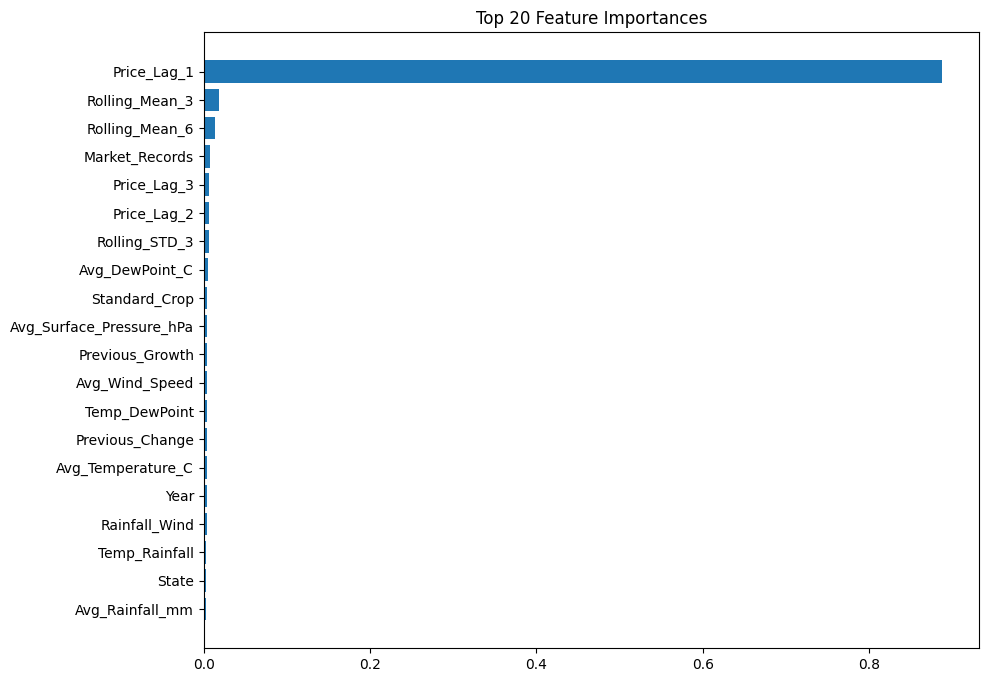

In [34]:
plt.figure(figsize=(10, 8))

plt.barh(
    importance["Feature"][:20],
    importance["Importance"][:20]
)

plt.gca().invert_yaxis()

plt.title("Top 20 Feature Importances")

plt.show()

### XGBoost Model

In [36]:
!pip install xgboost

   ---------------------------------------- 0.0/69.5 MB ? eta -:--:--
   ---------------------------------------- 0.8/69.5 MB 9.3 MB/s eta 0:00:08
   - -------------------------------------- 2.1/69.5 MB 6.4 MB/s eta 0:00:11
   -- ------------------------------------- 3.9/69.5 MB 7.7 MB/s eta 0:00:09
   --- ------------------------------------ 6.3/69.5 MB 8.6 MB/s eta 0:00:08
   ---- ----------------------------------- 7.6/69.5 MB 8.3 MB/s eta 0:00:08
   ----- ---------------------------------- 8.9/69.5 MB 8.0 MB/s eta 0:00:08
   ----- ---------------------------------- 9.4/69.5 MB 7.4 MB/s eta 0:00:09
   ----- ---------------------------------- 10.2/69.5 MB 6.6 MB/s eta 0:00:10
   ------ --------------------------------- 10.5/69.5 MB 6.3 MB/s eta 0:00:10
   ------ --------------------------------- 10.7/69.5 MB 5.9 MB/s eta 0:00:11
   ------ --------------------------------- 11.0/69.5 MB 5.3 MB/s eta 0:00:12
   ------ --------------------------------- 11.8/69.5 MB 4.9 MB/s eta 0:00:12
 


[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [37]:
from xgboost import XGBRegressor

In [38]:
xgb = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=500,
    learning_rate=0.05,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

In [39]:
xgb.fit(X_train, y_train)

,"objective objective: str | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'reg:squarederror'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_metho

In [40]:
y_pred_log = xgb.predict(X_test)

y_test_price = np.expm1(y_test)
y_pred_price = np.expm1(y_pred_log)

In [41]:
print("===== LOG SCALE =====")

print("MAE :", mean_absolute_error(y_test, y_pred_log))

print("RMSE :", np.sqrt(mean_squared_error(y_test, y_pred_log)))

print("R2 :", r2_score(y_test, y_pred_log))

===== LOG SCALE =====
MAE : 0.15728607731713104
RMSE : 0.3046271660913413
R2 : 0.8737881874854557


In [42]:
print("===== ORIGINAL PRICE =====")

print("MAE :", mean_absolute_error(y_test_price, y_pred_price))

print("RMSE :", np.sqrt(mean_squared_error(y_test_price, y_pred_price)))

print("R2 :", r2_score(y_test_price, y_pred_price))

===== ORIGINAL PRICE =====
MAE : 1050.8265287189308
RMSE : 20340.245697685208
R2 : 0.058057367715185104


In [43]:
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": xgb.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

importance.head(20)

,Feature,Importance
12,Price_Lag_1,0.475930
15,Rolling_Mean_3,0.313289
16,Rolling_Mean_6,0.085674
22,Previous_Growth,0.011900
21,Previous_Change,0.007891
13,Price_Lag_2,0.007632
19,Month_Sin,0.006815
20,Month_Cos,0.006581
14,Price_Lag_3,0.006518
11,Grid_Points,0.005569


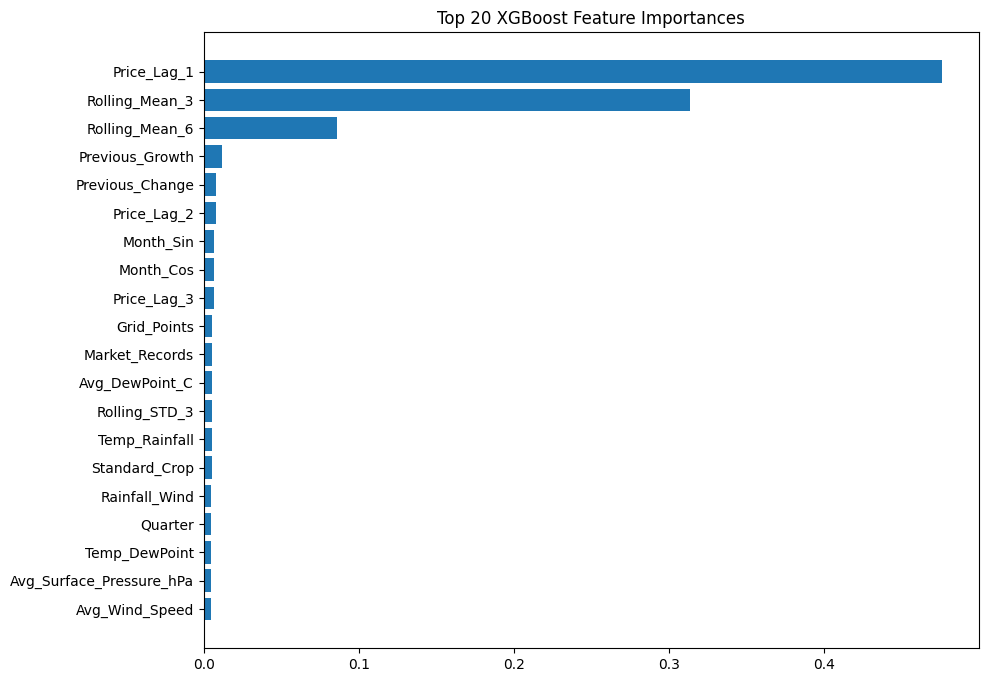

In [44]:
plt.figure(figsize=(10,8))

plt.barh(
    importance["Feature"][:20],
    importance["Importance"][:20]
)

plt.gca().invert_yaxis()

plt.title("Top 20 XGBoost Feature Importances")

plt.show()

### Catboost Model

In [45]:
!pip install catboost

   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.8/101.7 MB 5.9 MB/s eta 0:00:18
    --------------------------------------- 1.6/101.7 MB 4.9 MB/s eta 0:00:21
   - -------------------------------------- 2.6/101.7 MB 4.4 MB/s eta 0:00:23
   - -------------------------------------- 3.4/101.7 MB 4.3 MB/s eta 0:00:23
   - -------------------------------------- 3.9/101.7 MB 4.0 MB/s eta 0:00:25
   - -------------------------------------- 4.7/101.7 MB 3.8 MB/s eta 0:00:26
   -- ------------------------------------- 5.8/101.7 MB 4.1 MB/s eta 0:00:24
   -- ------------------------------------- 7.1/101.7 MB 4.3 MB/s eta 0:00:22
   --- ------------------------------------ 8.4/101.7 MB 4.5 MB/s eta 0:00:21
   --- ------------------------------------ 9.7/101.7 MB 4.7 MB/s eta 0:00:20
   ---- ----------------------------------- 11.5/101.7 MB 5.1 MB/s eta 0:00:18
   ----- ---------------------------------- 13.1/101.7 MB 5.3 MB/s eta


[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [46]:
from catboost import CatBoostRegressor

In [47]:
price = pd.read_parquet("../datasets/modeling/price_features.parquet")

In [48]:
drop_cols = [
    "Avg_Modal_Price",
    "Log_Price",
    "Median_Modal_Price",
    "Min_Modal_Price",
    "Max_Modal_Price",
    "Price_STD"
]

X = price.drop(columns=drop_cols)

y = price["Log_Price"]

In [49]:
train_mask = price["Year"] <= 2013
test_mask = price["Year"] > 2013

X_train = X[train_mask]
X_test = X[test_mask]

y_train = y[train_mask]
y_test = y[test_mask]

In [50]:
cat_features = [
    "State",
    "Standard_Crop"
]

In [51]:
cat_model = CatBoostRegressor(
    iterations=1000,
    learning_rate=0.05,
    depth=8,
    loss_function="RMSE",
    eval_metric="RMSE",
    random_seed=42,
    verbose=100
)

In [52]:
cat_model.fit(
    X_train,
    y_train,
    cat_features=cat_features
)

0:	learn: 0.8011146	total: 219ms	remaining: 3m 38s
100:	learn: 0.2663960	total: 9.97s	remaining: 1m 28s
200:	learn: 0.2531433	total: 18.9s	remaining: 1m 15s
300:	learn: 0.2444572	total: 28.2s	remaining: 1m 5s
400:	learn: 0.2372514	total: 38.9s	remaining: 58.1s
500:	learn: 0.2310978	total: 48.1s	remaining: 47.9s
600:	learn: 0.2258399	total: 57.5s	remaining: 38.2s
700:	learn: 0.2215480	total: 1m 9s	remaining: 29.8s
800:	learn: 0.2171914	total: 1m 20s	remaining: 20.1s
900:	learn: 0.2132892	total: 1m 30s	remaining: 9.99s
999:	learn: 0.2096657	total: 1m 40s	remaining: 0us


CatBoostRegressor(depth=8, eval_metric='RMSE', iterations=1000, learning_rate=0.05, loss_function='RMSE', random_seed=42, verbose=100)

In [53]:
y_pred_log = cat_model.predict(X_test)

y_test_price = np.expm1(y_test)
y_pred_price = np.expm1(y_pred_log)

In [54]:
print("===== LOG SCALE =====")

print("MAE :", mean_absolute_error(y_test, y_pred_log))
print("RMSE :", np.sqrt(mean_squared_error(y_test, y_pred_log)))
print("R2 :", r2_score(y_test, y_pred_log))

===== LOG SCALE =====
MAE : 0.15572125053484265
RMSE : 0.3003798629957794
R2 : 0.8772831008749513


In [55]:
print("===== ORIGINAL PRICE =====")

print("MAE :", mean_absolute_error(y_test_price, y_pred_price))
print("RMSE :", np.sqrt(mean_squared_error(y_test_price, y_pred_price)))
print("R2 :", r2_score(y_test_price, y_pred_price))

===== ORIGINAL PRICE =====
MAE : 1045.5081473183109
RMSE : 20386.74382897086
R2 : 0.05374585300153467


In [56]:
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": cat_model.get_feature_importance()
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

importance.head(20)

,Feature,Importance
12,Price_Lag_1,40.973095
15,Rolling_Mean_3,8.346648
16,Rolling_Mean_6,7.966097
3,Standard_Crop,7.547661
4,Market_Records,4.149131
13,Price_Lag_2,3.331911
22,Previous_Growth,3.187598
14,Price_Lag_3,3.142318
1,Year,2.725582
21,Previous_Change,2.674774


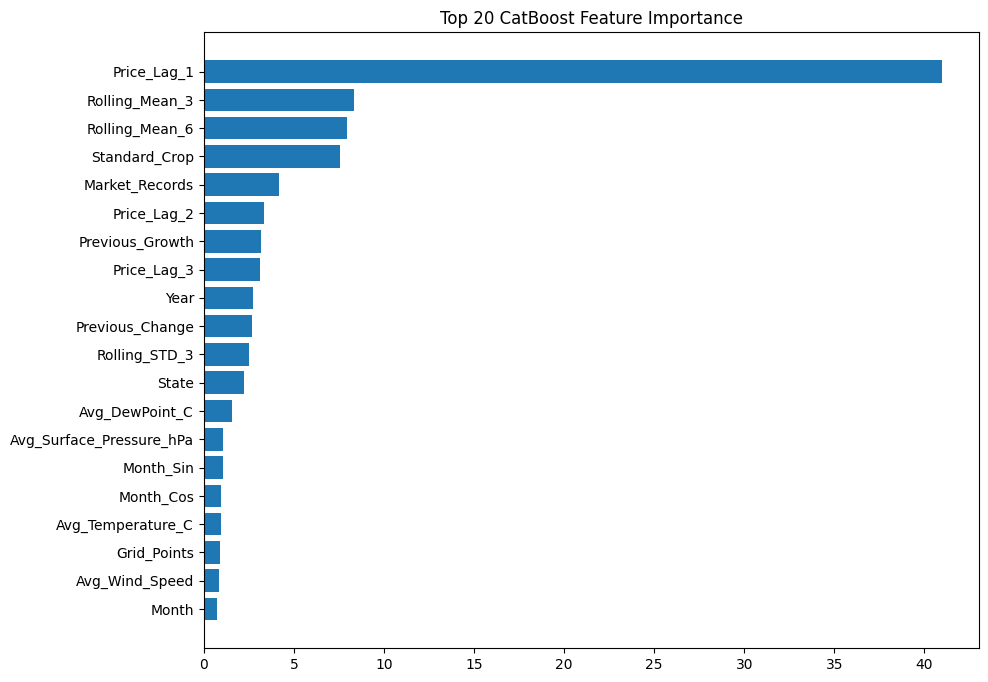

In [57]:
plt.figure(figsize=(10,8))

plt.barh(
    importance["Feature"][:20],
    importance["Importance"][:20]
)

plt.gca().invert_yaxis()

plt.title("Top 20 CatBoost Feature Importance")

plt.show()

In [58]:
crop_scores = (
    pd.DataFrame({
        "Crop": X_test["Standard_Crop"],
        "Actual": y_test_price,
        "Predicted": y_pred_price
    })
    .groupby("Crop")
    .apply(
        lambda df: mean_absolute_error(
            df["Actual"],
            df["Predicted"]
        )
    )
    .sort_values()
)

crop_scores.head(20)

Crop
Wheat            79.669538
Barley           83.604594
Maize            91.343204
Bajra            93.560334
Paddy           105.922148
Ragi            152.312561
Rice            155.965819
Potato          178.312171
Jowar           212.515871
Bottle Gourd    232.767431
Castor Seed     236.104007
Papaya          236.525255
Water Melon     238.092659
Sunflower       240.964060
Cabbage         240.979995
Banana          249.253078
Jute            249.604802
Soyabean        268.866945
Sweet Potato    269.789050
Groundnut       280.225089
dtype: float64

In [60]:
comparison = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost", "CatBoost"],

    "Log MAE": [
        0.162173,
        0.157286,
        0.155721
    ],

    "Log RMSE": [
        0.303817,
        0.304627,
        0.300380
    ],

    "Log R2": [
        0.874459,
        0.873788,
        0.877283
    ],

    "Price MAE": [
        983.82,
        1050.83,
        1045.51
    ],

    "Price RMSE": [
        20133.82,
        20340.25,
        20386.74
    ],

    "Price R2": [
        0.077079,
        0.058057,
        0.053746
    ]
})

comparison

,Model,Log MAE,Log RMSE,Log R2,Price MAE,Price RMSE,Price R2
0,Random Forest,0.162173,0.303817,0.874459,983.82,20133.82,0.077079
1,XGBoost,0.157286,0.304627,0.873788,1050.83,20340.25,0.058057
2,CatBoost,0.155721,0.300380,0.877283,1045.51,20386.74,0.053746


In [61]:
comparison.to_csv(
    "../models/model_comparison.csv",
    index=False
)

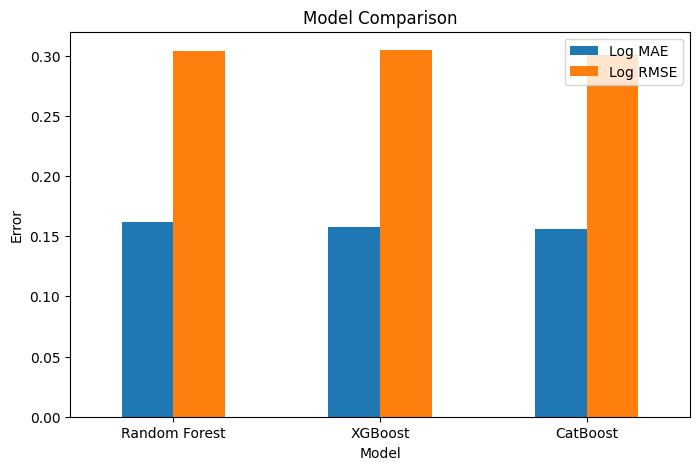

In [62]:
comparison.set_index("Model")[["Log MAE", "Log RMSE"]].plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Model Comparison")
plt.ylabel("Error")
plt.xticks(rotation=0)
plt.show()

In [64]:
import joblib

# Native CatBoost format
cat_model.save_model("../models/catboost_price_model.cbm")

# Pickle format
joblib.dump(cat_model, "../models/catboost_price_model.pkl")

['../models/catboost_price_model.pkl']

In [65]:
importance.to_csv(
    "../models/catboost_feature_importance.csv",
    index=False
)

In [66]:
crop_scores.to_csv(
    "../models/cropwise_mae.csv",
    header=["MAE"]
)

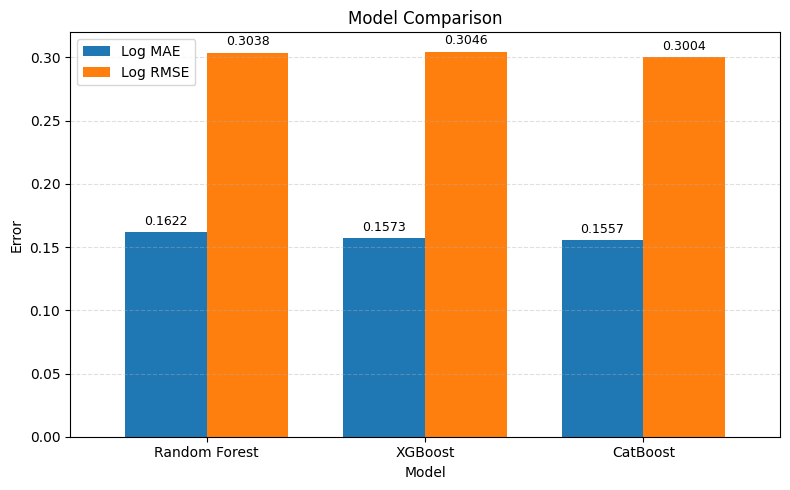

In [67]:
import matplotlib.pyplot as plt

ax = comparison.set_index("Model")[["Log MAE", "Log RMSE"]].plot(
    kind="bar",
    figsize=(8, 5),
    width=0.75
)

plt.title("Model Comparison")
plt.ylabel("Error")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.4)

# Add values on top of each bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.4f",
        padding=3,
        fontsize=9
    )

plt.tight_layout()
plt.show()

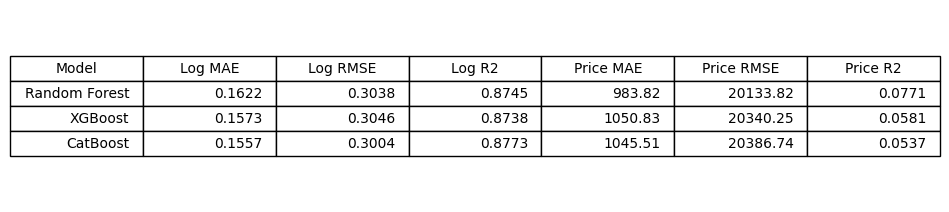

In [69]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 2.5))
ax.axis("off")

table = ax.table(
    cellText=comparison.round(4).values,
    colLabels=comparison.columns,
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 1.5)

plt.savefig("../reports/model_comparison_table.png", dpi=300, bbox_inches="tight")
plt.show()